<a href="https://colab.research.google.com/github/shriyyaaa/Brain--tumor--detection/blob/main/brain_tumor_detection_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain Tumor MRI Classification with Transfer Learning

Classifies MRI scans into **glioma, meningioma, pituitary, no tumor** using an ImageNet-pretrained CNN (ResNet50 / EfficientNet-B0) in PyTorch, with Grad-CAM heatmaps.

**Before you start:** Runtime → Change runtime type → **T4 GPU**.

> For learning and research only. Not a medical device; never use it for diagnosis.

## 1. Setup

In [1]:
import random, time, json, os
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU (enable a GPU runtime for speed)")

Device: cuda | Tesla T4


## 2. Download the dataset

Uses `kagglehub` (the dataset is public). If the download asks for credentials, see the fallback cell below it.

In [2]:
!pip -q install kagglehub
import kagglehub
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Downloaded to:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Downloaded to: /kaggle/input/brain-tumor-mri-dataset


In [3]:
# Fallback (only if the cell above fails): upload your kaggle.json (Kaggle > Settings > API > Create New Token)
# from google.colab import files
# files.upload()
# !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !kaggle datasets download -d masoudnickparvar/brain-tumor-mri-dataset -p data --unzip
# path = "data"

In [4]:
# Locate the folder that contains Training/ and Testing/
DATA_DIR = next(p.parent for p in Path(path).rglob("Training") if p.is_dir())
print("DATA_DIR:", DATA_DIR)
for split in ["Training", "Testing"]:
    for c in sorted((DATA_DIR / split).iterdir()):
        print(f"{split:9} {c.name:12} {len(list(c.glob('*')))}")

DATA_DIR: /kaggle/input/brain-tumor-mri-dataset
Training  glioma       1400
Training  meningioma   1400
Training  notumor      1400
Training  pituitary    1400
Testing   glioma       400
Testing   meningioma   400
Testing   notumor      400
Testing   pituitary    400


## 3. Look at the data

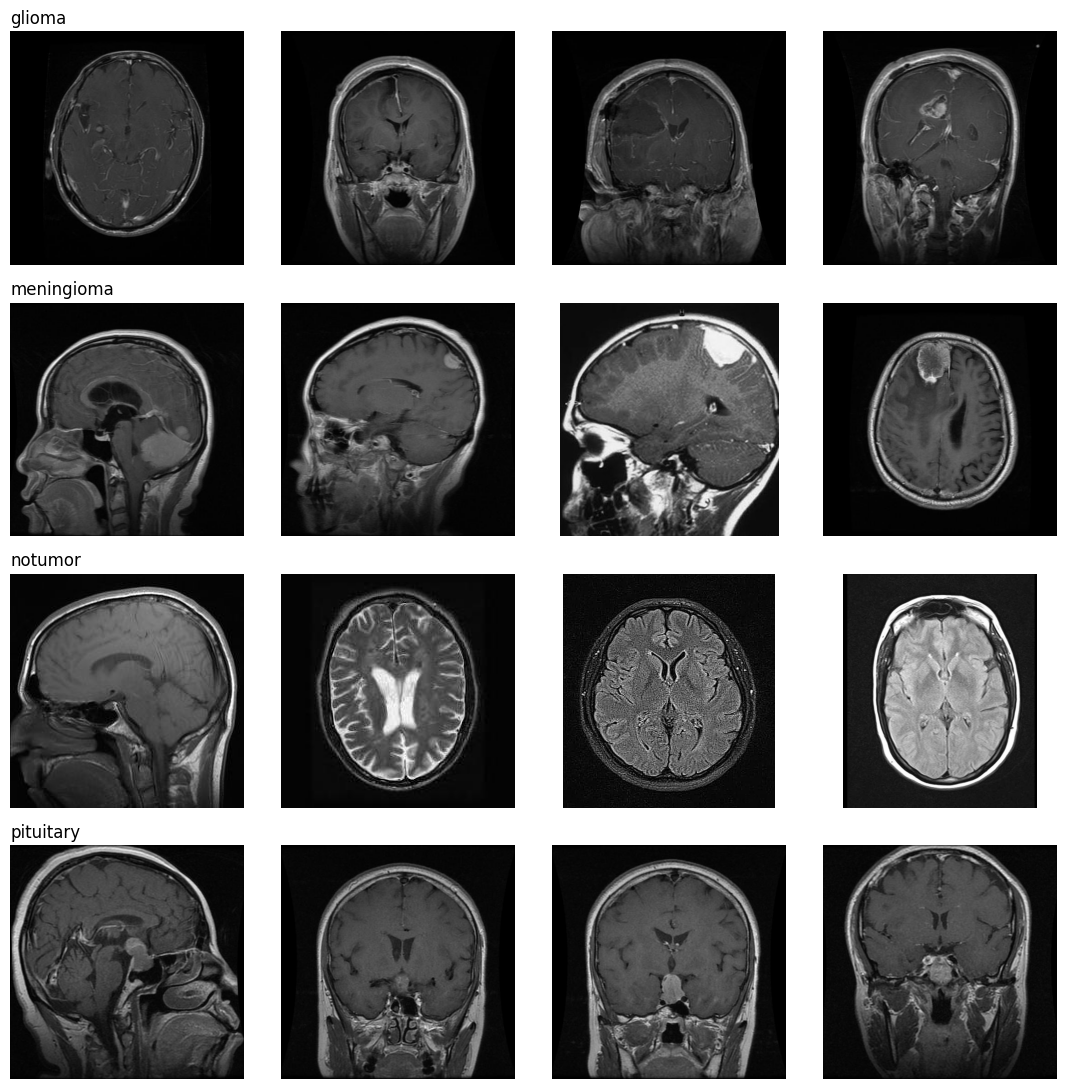

In [5]:
classes_preview = sorted(p.name for p in (DATA_DIR / "Training").iterdir())
fig, axes = plt.subplots(len(classes_preview), 4, figsize=(11, 11))
for r, c in enumerate(classes_preview):
    files = random.sample(list((DATA_DIR / "Training" / c).glob("*")), 4)
    for k, f in enumerate(files):
        axes[r, k].imshow(Image.open(f).convert("RGB"))
        axes[r, k].axis("off")
        if k == 0:
            axes[r, k].set_title(c, loc="left")
plt.tight_layout(); plt.show()

## 4. Config and data loaders

A stratified 15% of `Training/` is held out for validation. `Testing/` is only used at the very end.

In [6]:
ARCH        = "resnet50"      # "resnet50" or "efficientnet_b0"
IMG_SIZE    = 224
BATCH_SIZE  = 32
EPOCHS_HEAD = 5               # phase 1: backbone frozen
EPOCHS_FT   = 10              # phase 2: last blocks unfrozen
LR_HEAD     = 1e-3
LR_FT       = 1e-4
VAL_FRAC    = 0.15

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

full_train = datasets.ImageFolder(DATA_DIR / "Training", transform=train_tf)
full_val   = datasets.ImageFolder(DATA_DIR / "Training", transform=eval_tf)
test_ds    = datasets.ImageFolder(DATA_DIR / "Testing",  transform=eval_tf)
classes = full_train.classes

tr_idx, va_idx = train_test_split(np.arange(len(full_train)), test_size=VAL_FRAC,
                                  stratify=full_train.targets, random_state=SEED)
kw = dict(batch_size=BATCH_SIZE, num_workers=2, pin_memory=True)
train_loader = DataLoader(Subset(full_train, tr_idx), shuffle=True,  **kw)
val_loader   = DataLoader(Subset(full_val,   va_idx), shuffle=False, **kw)
test_loader  = DataLoader(test_ds,                    shuffle=False, **kw)

print("Classes:", classes)
print(f"train {len(tr_idx)} | val {len(va_idx)} | test {len(test_ds)}")

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
train 4760 | val 840 | test 1600


## 5. Build the model

In [7]:
def build_model(arch, num_classes, pretrained=True):
    """Returns (model, head_module, last_blocks_to_unfreeze)."""
    if arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if pretrained else None)
        m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, num_classes))
        return m, m.fc, [m.layer4]
    if arch == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None)
        m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, num_classes))
        return m, m.classifier, [m.features[6], m.features[7], m.features[8]]
    raise ValueError(arch)

def set_trainable(model, modules):
    for p in model.parameters():
        p.requires_grad = False
    for mod in modules:
        for p in mod.parameters():
            p.requires_grad = True

model, head, last_blocks = build_model(ARCH, len(classes))
model.to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 105MB/s]


## 6. Train (two-phase transfer learning)

1. **Phase 1:** freeze the pretrained backbone and train only the new head.
2. **Phase 2:** unfreeze the last blocks and fine-tune at a lower learning rate.

In [8]:
def run_epoch(model, loader, optimizer=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    use_amp = device.type == "cuda"
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best = {"acc": 0.0, "weights": None}

def fit_phase(name, epochs, lr):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, optimizer, scaler)
        vl, va = run_epoch(model, val_loader)
        scheduler.step()
        for k, v in zip(history, (tl, ta, vl, va)):
            history[k].append(v)
        improved = va > best["acc"]
        if improved:
            best["acc"] = va
            best["weights"] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] {ep}/{epochs}  train {tl:.4f}/{ta:.4f}  val {vl:.4f}/{va:.4f}  ({time.time()-t0:.0f}s){'  *' if improved else ''}")

# Phase 1
set_trainable(model, [head])
fit_phase("head", EPOCHS_HEAD, LR_HEAD)

# Phase 2
set_trainable(model, [head] + last_blocks)
fit_phase("finetune", EPOCHS_FT, LR_FT)

model.load_state_dict(best["weights"])
print(f"\nBest validation accuracy: {best['acc']:.4f}")

[head] 1/5  train 0.9216/0.7416  val nan/0.8381  (47s)  *
[head] 2/5  train 0.7182/0.8330  val nan/0.8667  (33s)  *
[head] 3/5  train 0.6929/0.8420  val 0.6815/0.8714  (33s)  *
[head] 4/5  train 0.6748/0.8546  val nan/0.8631  (32s)
[head] 5/5  train 0.6560/0.8624  val 0.6848/0.8738  (33s)  *
[finetune] 1/10  train 0.5806/0.8931  val nan/0.9333  (33s)  *
[finetune] 2/10  train 0.4915/0.9403  val 0.4788/0.9560  (37s)  *
[finetune] 3/10  train 0.4527/0.9639  val nan/0.9631  (34s)  *
[finetune] 4/10  train 0.4317/0.9737  val 0.4368/0.9726  (34s)  *
[finetune] 5/10  train 0.4130/0.9811  val 0.4427/0.9702  (34s)
[finetune] 6/10  train 0.4038/0.9845  val 0.4218/0.9798  (32s)  *
[finetune] 7/10  train 0.3989/0.9857  val 0.4186/0.9786  (34s)
[finetune] 8/10  train 0.3959/0.9880  val nan/0.9726  (33s)
[finetune] 9/10  train 0.3904/0.9920  val nan/0.9762  (34s)
[finetune] 10/10  train 0.3883/0.9908  val nan/0.9774  (33s)

Best validation accuracy: 0.9798


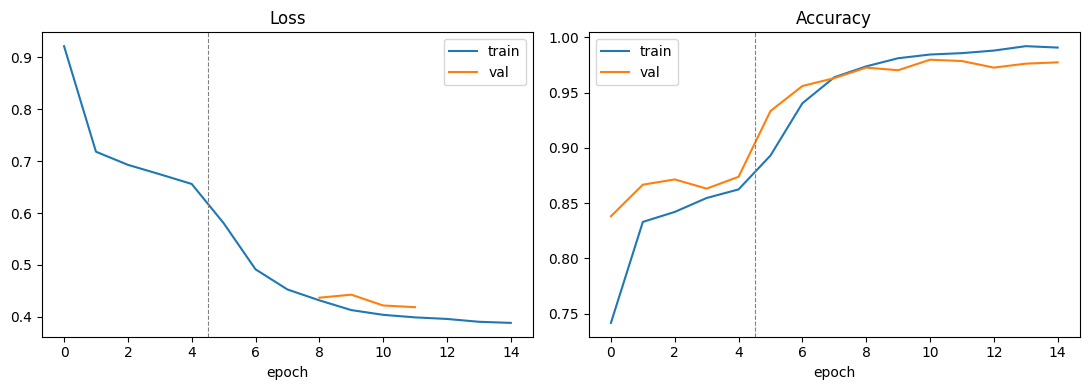

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, key, title in zip(ax, ["loss", "acc"], ["Loss", "Accuracy"]):
    a.plot(history[f"train_{key}"], label="train")
    a.plot(history[f"val_{key}"], label="val")
    a.axvline(EPOCHS_HEAD - 0.5, color="gray", ls="--", lw=0.8)  # start of fine-tuning
    a.set_title(title); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.show()

## 7. Evaluate on the held-out test set

              precision    recall  f1-score   support

      glioma     0.9849    0.8175    0.8934       400
  meningioma     0.9244    0.9475    0.9358       400
     notumor     0.8869    1.0000    0.9401       400
   pituitary     0.9779    0.9950    0.9864       400

    accuracy                         0.9400      1600
   macro avg     0.9435    0.9400    0.9389      1600
weighted avg     0.9435    0.9400    0.9389      1600



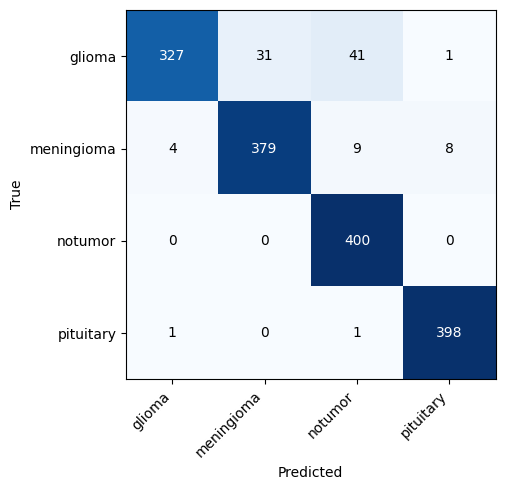

In [10]:
@torch.no_grad()
def predict_loader(loader):
    model.eval()
    preds, labels = [], []
    for x, y in loader:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        labels += y.tolist()
    return np.array(labels), np.array(preds)

y_true, y_pred = predict_loader(test_loader)
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(classes)), classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes)), classes)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(len(classes)):
    for j in range(len(classes)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()

## 8. Grad-CAM: what is the model looking at?

Heatmaps highlight the regions that most influenced the prediction. Useful for sanity-checking that the model focuses on the lesion and not on artifacts like borders or text.

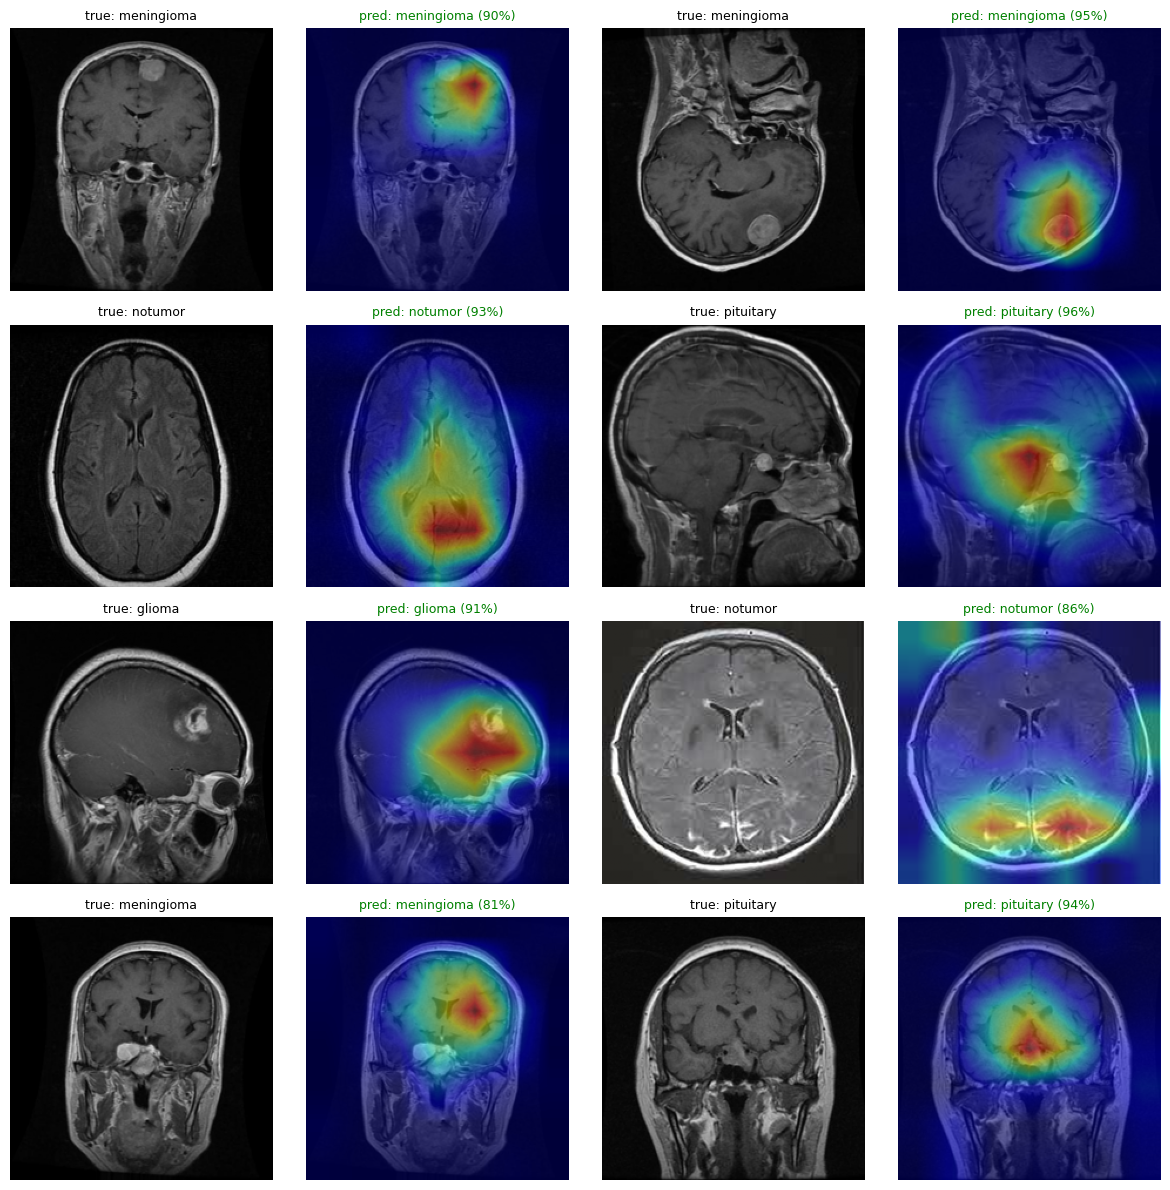

In [11]:
class GradCAM:
    def __init__(self, layer):
        self.acts = self.grads = None
        layer.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.acts = out.detach()
        out.register_hook(lambda g: setattr(self, "grads", g.detach()))
    def heatmap(self, size):
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=size, mode="bilinear", align_corners=False)[0, 0]
        cam -= cam.min(); cam /= cam.max() + 1e-8
        return cam.cpu().numpy()

target_layer = model.layer4[-1] if ARCH == "resnet50" else model.features[-1]
cam_tool = GradCAM(target_layer)

def explain(img):
    """img: PIL image -> (probs, predicted_idx, base_rgb, overlay_rgb)"""
    x = eval_tf(img.convert("RGB")).unsqueeze(0).to(device)
    model.eval()
    with torch.enable_grad():
        logits = model(x)
        probs = logits.softmax(1)[0].detach().cpu()
        pred = int(probs.argmax())
        model.zero_grad()
        logits[0, pred].backward()
    heat = cam_tool.heatmap((IMG_SIZE, IMG_SIZE))
    base = np.asarray(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))) / 255.0
    overlay = 0.55 * base + 0.45 * plt.get_cmap("jet")(heat)[..., :3]
    return probs, pred, base, overlay

# 8 random test images
samples = random.sample(range(len(test_ds)), 8)
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for k, idx in enumerate(samples):
    path_i, true_i = test_ds.samples[idx]
    probs, pred, base, overlay = explain(Image.open(path_i))
    r, c = divmod(k, 2)
    axes[r, c * 2].imshow(base); axes[r, c * 2].axis("off")
    axes[r, c * 2].set_title(f"true: {classes[true_i]}", fontsize=9)
    axes[r, c * 2 + 1].imshow(overlay); axes[r, c * 2 + 1].axis("off")
    color = "green" if pred == true_i else "red"
    axes[r, c * 2 + 1].set_title(f"pred: {classes[pred]} ({probs[pred]:.0%})", fontsize=9, color=color)
plt.tight_layout(); plt.show()

## 9. Try your own MRI image

Saving Te-pi_140.jpg to Te-pi_140.jpg


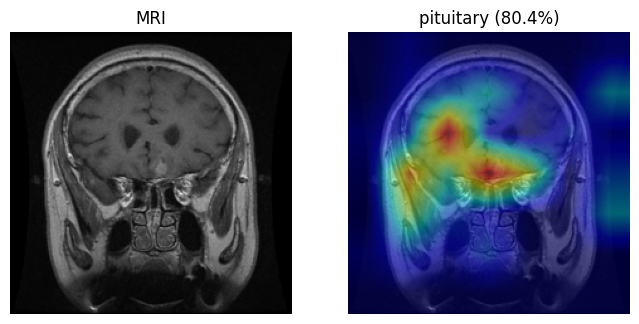

  pituitary    80.4%
  glioma       9.7%
  meningioma   5.5%
  notumor      4.3%


In [12]:
from google.colab import files
up = files.upload()
for name in up:
    probs, pred, base, overlay = explain(Image.open(name))
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(base); ax[0].set_title("MRI")
    ax[1].imshow(overlay); ax[1].set_title(f"{classes[pred]} ({probs[pred]:.1%})")
    for a in ax: a.axis("off")
    plt.show()
    for c, p in sorted(zip(classes, probs.tolist()), key=lambda t: -t[1]):
        print(f"  {c:<12} {p:.1%}")

## 10. Save the model

In [13]:
torch.save({"model_state": best["weights"], "arch": ARCH, "classes": classes, "img_size": IMG_SIZE},
           "best_model.pt")
files.download("best_model.pt")
# Or keep it in Google Drive:
# from google.colab import drive; drive.mount("/content/drive")
# !cp best_model.pt /content/drive/MyDrive/

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>